TokaMaker Example: TCS FRC equilibrium {#doc_tMaker_TCS_ex2}
==========
In this example we demonstrate how to create a field-reversed configuration (FRC) equilibrium for the Translation, Confinement, and Sustainment (TCS) experiment [[A. L. Hoffman et al. (2002)](https://doi.org/10.13182/FST02-A205)].

This example utilizes the mesh built in \ref doc_tMaker_TCS_ex1.

**Note:** Running this example requires the [h5py](https://www.h5py.org/) python package, which is installable using `pip` or other standard methods.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

## Load TokaMaker library

To load the TokaMaker python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or using within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.TokaMaker import TokaMaker
from OpenFUSIONToolkit.TokaMaker.meshing import load_gs_mesh
from OpenFUSIONToolkit.TokaMaker.util import create_spline_flux_fun
from OpenFUSIONToolkit.util import mu0

## Setup calculation

### Initialize TokaMaker object
We now create a \ref OpenFUSIONToolkit.OFT_env "OFT_env" instance for execution using four threads and a \ref OpenFUSIONToolkit.TokaMaker.TokaMaker "TokaMaker" instance to use for equilibrium calculations.

In [3]:
myOFT = OFT_env(nthreads=4)
mygs = TokaMaker(myOFT)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/



Base release:        v26.9
Development branch:  claude/tokamak-tcs-example-94e0b2
Revision id:         cd26e207

Parallelization Info:
  # of MPI tasks      =    1
  # of NUMA nodes     =    1
  # of OpenMP threads =    4

Linear Algebra backend: native

#----------------------------------------------



### Load mesh into TokaMaker
Now we load the mesh generated in \ref doc_tMaker_TCS_ex1 using \ref OpenFUSIONToolkit.TokaMaker.load_gs_mesh "load_gs_mesh()" and \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup_mesh "setup_mesh". Then we use \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup_regions "setup_regions()", passing the conductor and coil dictionaries for the mesh, to define the different region types. Finally, we call \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup "setup()" to setup the required solver objects. During this call we can specify the desired element order (min=2, max=4).

As FRCs are long and thin we also set `settings.rotate_plots=True`, which places $Z$ on the horizontal axis in TokaMaker's plotting methods (eg. \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.plot_machine "plot_machine()" and \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.plot_psi "plot_psi()"). This only affects plotting and does not change the calculation.

**Note:** Here we use 3rd order elements (`order=3`) as the hollow current profiles used below, which concentrate current near the separatrix, and the axial symmetry constraints require higher spatial resolution than the default (`order=2`) provides on this mesh.

In [4]:
mesh_pts,mesh_lc,mesh_reg,coil_dict,cond_dict = load_gs_mesh('TCS_mesh.h5')
mygs.settings.rotate_plots = True # Plot with Z on the horizontal axis
mygs.setup_mesh(mesh_pts, mesh_lc, mesh_reg)
mygs.setup_regions(cond_dict=cond_dict,coil_dict=coil_dict)
mygs.setup(order=3)


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  3.200E+00
    # of points  =   10896
    # of edges   =   32347
    # of cells   =   21452
    # of boundary points =     338
    # of boundary edges  =     338
    # of boundary cells  =     338
  Resolution statistics:
    hmin =  6.250E-03
    hrms =  1.969E-02
    hmax =  7.413E-02
  Surface grounded at vertex     943


**** Creating Lagrange FE space
  Order  =    3
  Minlev =   -1

 Computing flux BC matrix 


 Inverting real matrix
   Time =    3.9919000000000003E-002


### Solve for vacuum field
Each coil in the TCS mesh is an independent coil. However, for the initial vacuum (bias) field we want a uniform current in all of the coils in each of the three coil groups (`CENTRAL`, `END`, and `MIRROR`). We first build a list of the coils in each group using the coil names.

In [5]:
coil_groups = {}
for coil_name in coil_dict:
    group_name = coil_name.rstrip('0123456789')
    coil_groups.setdefault(group_name,[]).append(coil_name)
for group_name, coil_names in coil_groups.items():
    print('{0:8} {1}'.format(group_name,', '.join(coil_names)))

END      END1, END2, END3, END18, END19, END20
CENTRAL  CENTRAL4, CENTRAL5, CENTRAL6, CENTRAL7, CENTRAL8, CENTRAL9, CENTRAL10, CENTRAL11, CENTRAL12, CENTRAL13, CENTRAL14, CENTRAL15, CENTRAL16, CENTRAL17
MIRROR   MIRROR1, MIRROR2


We now choose the current in each group to give a target axial field ($B_z$) at several points along the geometric axis:
 - $B_z = -0.10$ T at $Z = 0$ (midplane)
 - $B_z = -0.12$ T at $Z = \pm 1.0$ m (end coils)
 - $B_z = -0.20$ T at $Z = \pm 1.45$ m (cone mirror coils)

The bias field is chosen to point in the $-\hat{z}$ direction so that the FRC is formed by a positive toroidal plasma current, consistent with TokaMaker's sign convention.

As the vacuum field is linear in the coil currents we can find the required currents by computing the field from a unit current (1 A in each coil of a group) for each group using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.vac_solve "vac_solve()". This gives a response matrix relating the group currents to the field at each target point, which we then invert in a least-squares sense.

**Note:** The field is evaluated slightly off axis ($R = 1$ cm) to avoid the coordinate singularity at $R = 0$.

In [6]:
# Target axial field at points along the axis
target_z = np.r_[0.0, -1.0, 1.0, -1.45, 1.45]
target_Bz = -np.r_[0.10, 0.12, 0.12, 0.20, 0.20]
eval_r = 1.E-2

# Compute field response to unit current in each group
group_names = list(coil_groups.keys())
Bz_resp = np.zeros((target_z.shape[0],len(group_names)))
for j, group_name in enumerate(group_names):
    mygs.set_coil_currents({coil_name: 1.0 for coil_name in coil_groups[group_name]})
    EQ_unit = mygs.vac_solve()
    mygs.set_psi(EQ_unit.get_psi(False))
    field_eval = mygs.get_field_eval('B')
    for i, z in enumerate(target_z):
        Bz_resp[i,j] = field_eval.eval(np.r_[eval_r,z])[2]

# Solve for group currents
group_currents = np.linalg.lstsq(Bz_resp,target_Bz,rcond=None)[0]
for group_name, current in zip(group_names,group_currents):
    print('I_{0:8} = {1:8.2f} [A] ({2:6.2f} [kA-turns/coil])'.format(group_name,current,current*coil_dict[coil_groups[group_name][0]]['nturns']/1.E3))

   1  6.0203E-06
   1  3.7386E-05
   1  1.3961E-06
I_END      =  -219.01 [A] (-12.26 [kA-turns/coil])
I_CENTRAL  =  -186.52 [A] (-10.45 [kA-turns/coil])
I_MIRROR   =  -739.84 [A] (-89.52 [kA-turns/coil])


Finally, we set the resulting currents in all of the coils, compute the corresponding vacuum field, and compare the field at each of the target points.

In [7]:
# Set coil currents and solve for vacuum field
coil_currents = {}
for group_name, current in zip(group_names,group_currents):
    for coil_name in coil_groups[group_name]:
        coil_currents[coil_name] = current
mygs.set_coil_currents(coil_currents)
EQ_vac = mygs.vac_solve()
psi_vac = EQ_vac.get_psi(False)

# Get B-field at target points
mygs.set_psi(psi_vac)
field_eval = mygs.get_field_eval('B')
for z, Bz_target in zip(target_z,target_Bz):
    B = field_eval.eval(np.r_[eval_r,z])
    print('B_z(Z = {0:5.2f}) = {1:6.3f} [T] (target: {2:6.3f})'.format(z,B[2],Bz_target))

   1  3.9808E+00
B_z(Z =  0.00) = -0.100 [T] (target: -0.100)
B_z(Z = -1.00) = -0.120 [T] (target: -0.120)
B_z(Z =  1.00) = -0.120 [T] (target: -0.120)
B_z(Z = -1.45) = -0.200 [T] (target: -0.200)
B_z(Z =  1.45) = -0.200 [T] (target: -0.200)


We now plot the resulting vacuum flux surfaces along with the current in each coil, as well as the axial field along the geometric axis within the plasma region.

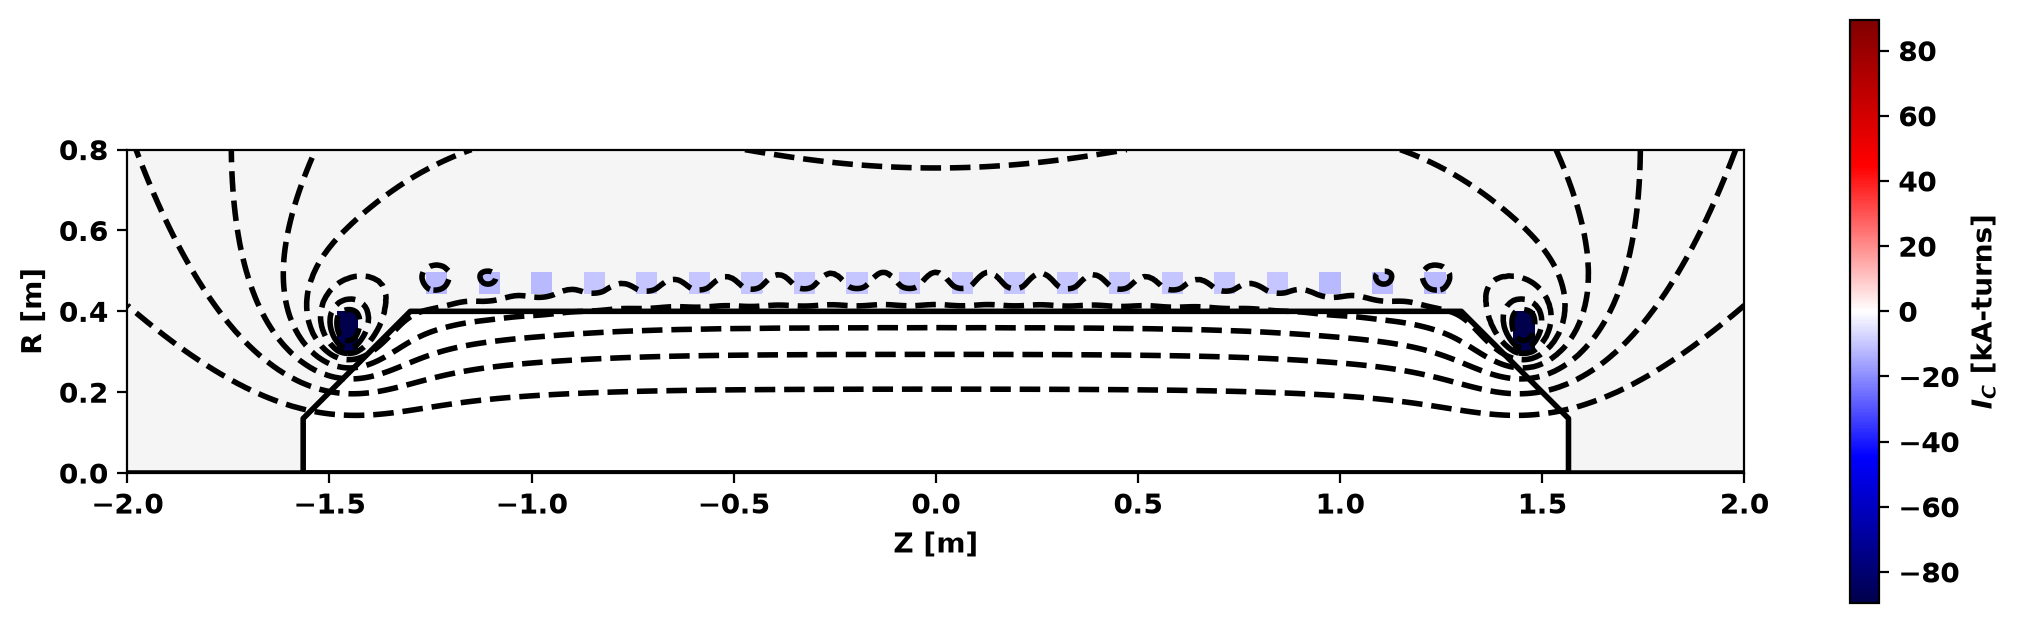

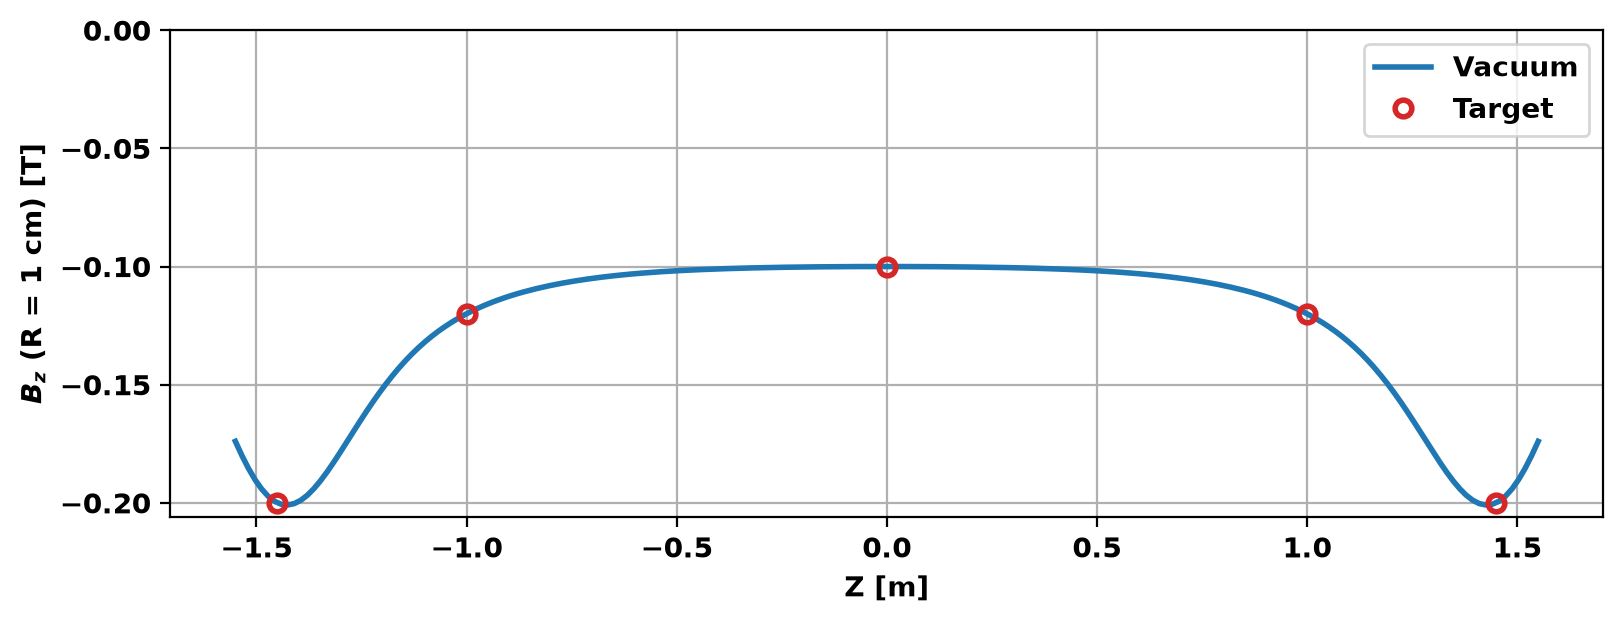

In [8]:
# Plot flux surfaces
fig, ax = plt.subplots(1,1,figsize=(10,3),constrained_layout=True)
mygs.plot_machine(fig,ax,coil_colormap='seismic',coil_symmap=True,coil_scale=1.E-3,coil_clabel=r'$I_C$ [kA-turns]')
mygs.plot_psi(fig,ax,psi=psi_vac,normalized=False,plasma_nlevels=10,plasma_color='k',vacuum_nlevels=0,xpoint_color=None,opoint_color=None)
ax.set_xlabel('Z [m]')
ax.set_ylabel('R [m]')

# Plot axial field on axis
z_axis = np.linspace(-1.55,1.55,200)
Bz_vac = np.zeros(z_axis.shape)
for i, z in enumerate(z_axis):
    Bz_vac[i] = field_eval.eval(np.r_[eval_r,z])[2]
fig, ax = plt.subplots(1,1,figsize=(8,3),constrained_layout=True)
ax.plot(z_axis,Bz_vac,label='Vacuum')
ax.plot(target_z,target_Bz,'o',color='tab:red',fillstyle='none',label='Target')
ax.set_ylim(top=0.0)
ax.grid(True)
ax.legend()
ax.set_xlabel('Z [m]')
_ = ax.set_ylabel(r'$B_z$ (R = 1 cm) [T]')

### Define flux functions
We now define the $P'$ profile using a cubic spline with \ref OpenFUSIONToolkit.TokaMaker.util.create_spline_flux_fun "create_spline_flux_fun()". The spline is defined by three "knots": on the magnetic axis ($\hat{\psi} = 0$, the field null), at an intermediate location ($\hat{\psi} = $ `pp_knot`), and at the separatrix ($\hat{\psi} = 1$), with zero slope at both ends. The middle knot controls the location of the maximum in $P'$, which lies between the axis and the knot (eg. $\hat{\psi} \approx 0.57$ for `pp_knot = 0.75`) and moves toward the separatrix as `pp_knot` is increased. The profile is normalized to its value on the axis, so only the relative shape matters, while the overall amplitude is set by the plasma current target during the solve.

**Try it yourself:** The location of the maximum in $P'$, set here using `pp_knot`, has a strong effect on the shape of the FRC. As $J_{\phi} = R P'$ when $F*F' = 0$, moving the maximum toward the separatrix (larger `pp_knot`) produces a hollow current profile concentrated near the separatrix, which is thought to be typical of TCS FRCs (Sec. VI of [Hoffman et al. (2002)](https://doi.org/10.13182/FST02-A205)), and results in a smaller, more elongated FRC with less trapped flux. Moving the maximum toward the field null (smaller `pp_knot`) instead produces a larger, rounder FRC. For example, with the 200 kA plasma current used below:

| `pp_knot` | $\hat{\psi}$ of max $P'$ | $r_s$ [m] | $l_s$ [m] | $l_s / 2 r_s$ | $\phi_p$ [mWb] |
|-----------|--------------------------|-----------|-----------|---------------|----------------|
| 0.25      | 0.37                     | 0.35      | 0.67      | 0.95          | 22.1           |
| 0.50      | 0.47                     | 0.34      | 0.69      | 1.01          | 19.5           |
| 0.75      | 0.57                     | 0.31      | 0.76      | 1.21          | 12.2           |

Try changing `pp_knot` below and re-running the rest of the notebook to see this for yourself. Note that very hollow profiles (eg. `pp_knot = 0.9`) may fail to converge without additional resolution.

FRCs have no toroidal field, so all of the plasma current must come from the $P'$ term and $\beta_p = 1$. As we will constrain the $F*F'$ contribution to the current to be zero during the solve, we must still define a profile for $F*F'$; here we use a simple flat profile.

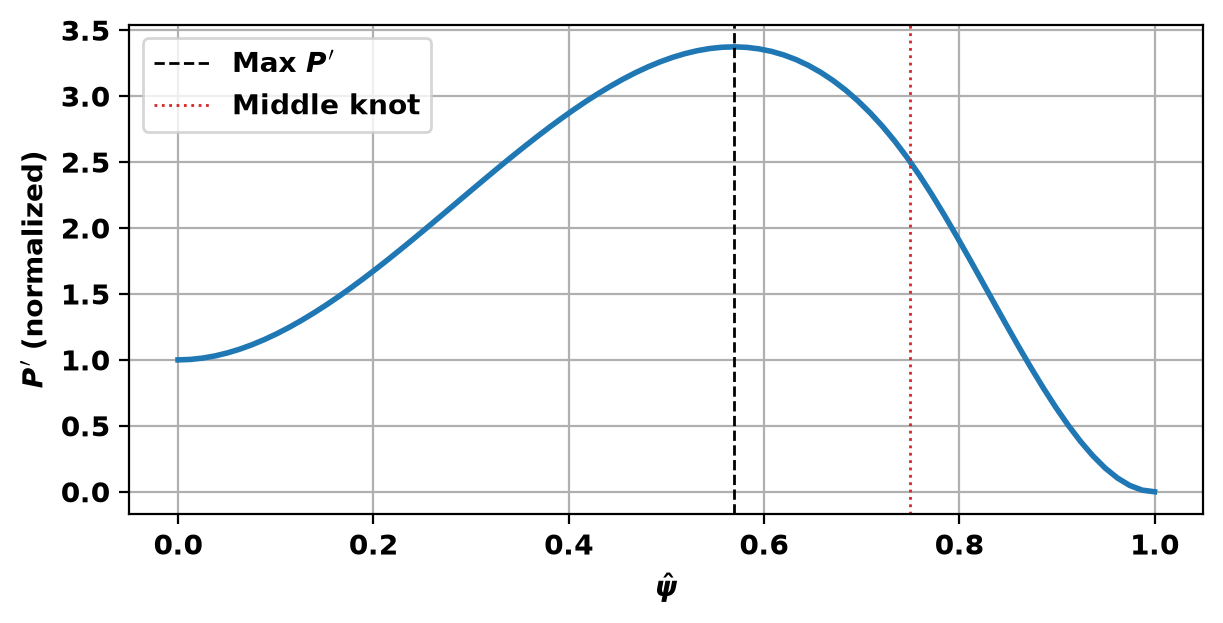

In [9]:
pp_knot = 0.75 # Location of middle spline knot, which sets the location of the maximum in P' (try varying this!)
pp_prof = create_spline_flux_fun(80,[0.0,pp_knot,1.0],[0.2,0.5,0.0],axis_bc=[1,0.0],edge_bc=[1,0.0])

ffp_prof = {'type': 'flat'}

mygs.set_profiles(ffp_prof=ffp_prof,pp_prof=pp_prof)

# Plot P' profile
fig, ax = plt.subplots(1,1,figsize=(6,3),constrained_layout=True)
ax.plot(pp_prof['x'],pp_prof['y'])
ax.axvline(pp_prof['x'][pp_prof['y'].argmax()],color='k',ls='--',lw=1,label=r"Max $P'$")
ax.axvline(pp_knot,color='tab:red',ls=':',lw=1,label='Middle knot')
ax.legend()
ax.grid(True)
ax.set_xlabel(r'$\hat{\psi}$')
_ = ax.set_ylabel(r"$P'$ (normalized)")

### Flux-conserving coils
In TCS the axial field coils act as a flux conserver on the timescale of FRC formation and translation, with an effective flux conserver radius of ~47 cm (Sec. III of [Hoffman et al. (2002)](https://doi.org/10.13182/FST02-A205)). As a result, the flux linked by each coil stays (approximately) fixed when the FRC is present and the coil currents change to compress the external field.

We model this by constraining $\psi$ at the centroid of each coil to its value in the vacuum field using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_psi_constraints "set_psi_constraints()". As there is one constraint for each coil this uniquely determines the coil currents, which are now free to vary during the solve. A very weak regularization toward the vacuum currents is also added using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_coil_reg "set_coil_reg()" to keep the coil fit well posed.

These constraints are set before initializing $\psi$ so that they are applied during both the initialization and the equilibrium solve.

In [10]:
# Compute centroid of each coil from the mesh
cell_centers = mygs.r[mygs.lc,:2].mean(axis=1)
coil_names = list(coil_dict.keys())
coil_pts = np.zeros((len(coil_names),2))
for i, coil_name in enumerate(coil_names):
    coil_pts[i,:] = cell_centers[mygs.reg == coil_dict[coil_name]['reg_id'],:].mean(axis=0)

# Evaluate vacuum flux at each coil
psi_vac_eval = mygs.get_field_eval('eval',values=psi_vac)
psi_coils = np.zeros((len(coil_names),))
for i, pt in enumerate(coil_pts):
    psi_coils[i] = psi_vac_eval.eval(pt)[0]

# Set flux constraints and weak regularization toward vacuum currents
mygs.set_psi_constraints(coil_pts,psi_coils)
reg_terms = []
for coil_name in coil_names:
    reg_terms.append(mygs.coil_reg_term({coil_name: 1.0},target=coil_currents[coil_name],weight=1.E-8))
mygs.set_coil_reg(reg_terms=reg_terms)

### Axial position control
The FRC is unstable to axial (vertical) shifts in this configuration, which prevents the solver from converging at higher plasma currents as the FRC slowly drifts along $Z$ during the nonlinear iterations. To prevent this we add a line of isoflux constraints using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_isoflux_constraints "set_isoflux_constraints()", where each point along a line in $Z$ (for $Z \geq 0$) is paired with a reference point reflected across $Z = 0$. This requires each pair of points to lie on the same flux surface, enforcing up-down symmetry of the equilibrium.

**Note:** As these constraints are also satisfied by adjusting the coil currents, the flux linked by each coil is no longer exactly conserved, but is instead matched in a least-squares sense along with the symmetry constraints.

In [11]:
# Points along R = 0.15 m for Z >= 0 and reference points reflected across Z = 0
sym_pts = np.zeros((20,2))
sym_pts[:,0] = 0.15
sym_pts[:,1] = np.linspace(0.0,0.5,sym_pts.shape[0])
sym_pts_ref = sym_pts.copy()
sym_pts_ref[:,1] *= -1.0
mygs.set_isoflux_constraints(sym_pts,weights=1.E1*np.ones((sym_pts.shape[0],)),ref_points=sym_pts_ref)

### Initialize $\psi$
Next we initialize $\psi$ using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.init_psi "init_psi()", which computes the flux from a uniform plasma current density inside an elliptical region defined by a center ($R_0$, $Z_0$), minor radius ($a$), and elongation ($\kappa$). As flux constraints are defined, the coil currents are also adjusted to conserve the flux linked by each coil.

To reverse the field the plasma current per unit length must be roughly $2 |B_e| / \mu_0$, where $B_e$ is the external field. For a ~0.75-m-long FRC in a ~0.17 T external field this gives a plasma current of ~200 kA. The size of the current region is chosen to be comparable to the translated FRCs in Table I of [Hoffman et al. (2002)](https://doi.org/10.13182/FST02-A205), which have separatrix radii of $r_s \approx 0.16 - 0.25$ m.

Here we also set the targets for the equilibrium solve: the plasma current and `Ip_ratio`, which is the ratio of the $F*F'$ and $P'$ contributions to the plasma current. Setting `Ip_ratio=0` ensures that all of the plasma current comes from $P'$ ($\beta_p = 1$).

In [12]:
mygs.set_targets(Ip=2.E5,Ip_ratio=0.0)
mygs.init_psi(r0=0.15,z0=0.0,a=0.12,kappa=2.0)
psi_init = mygs.get_psi(False)
psi_init_norm = mygs.get_psi()

We now plot the initial flux surfaces and compare the axial field to the vacuum field, which shows the reversal of the field in the center of the FRC. As $\psi = 0$ on the geometric axis ($R = 0$), the separatrix corresponds to the $\psi = 0$ contour.

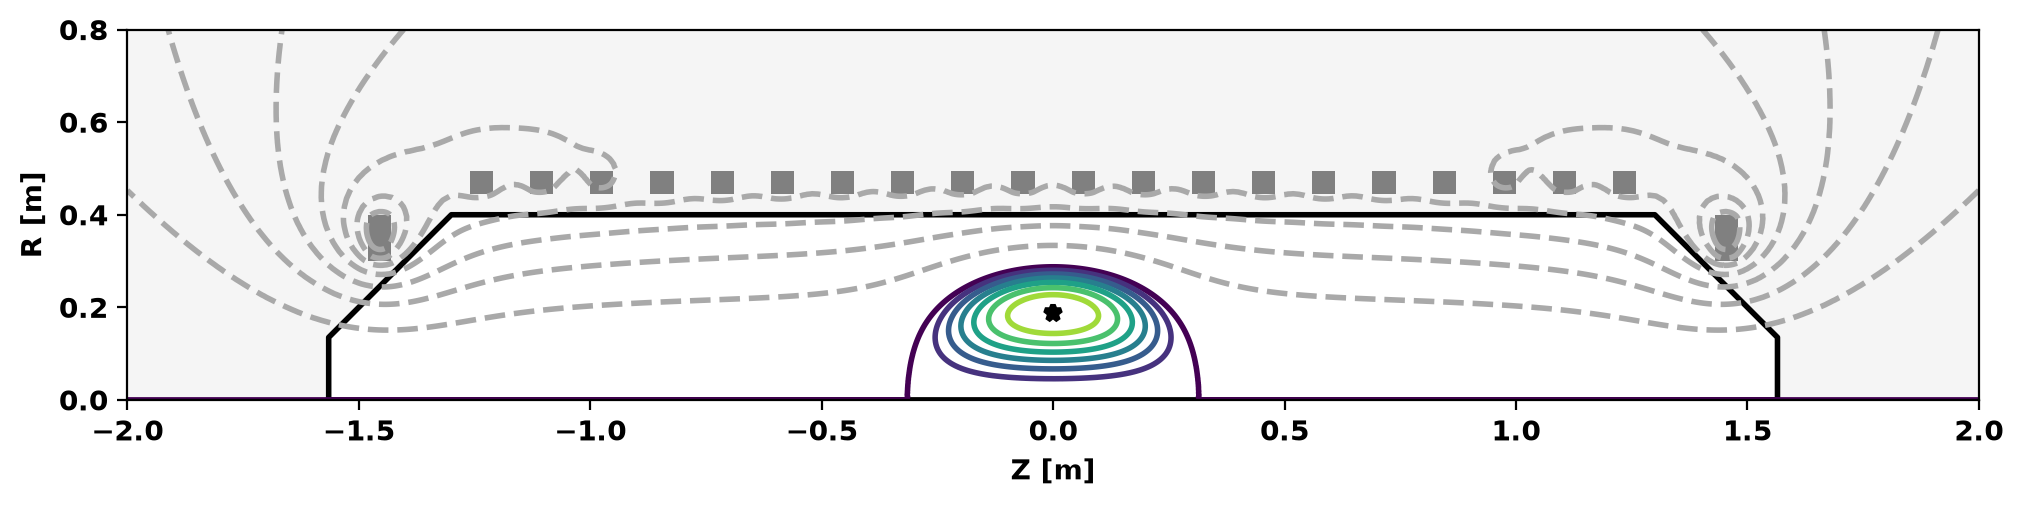

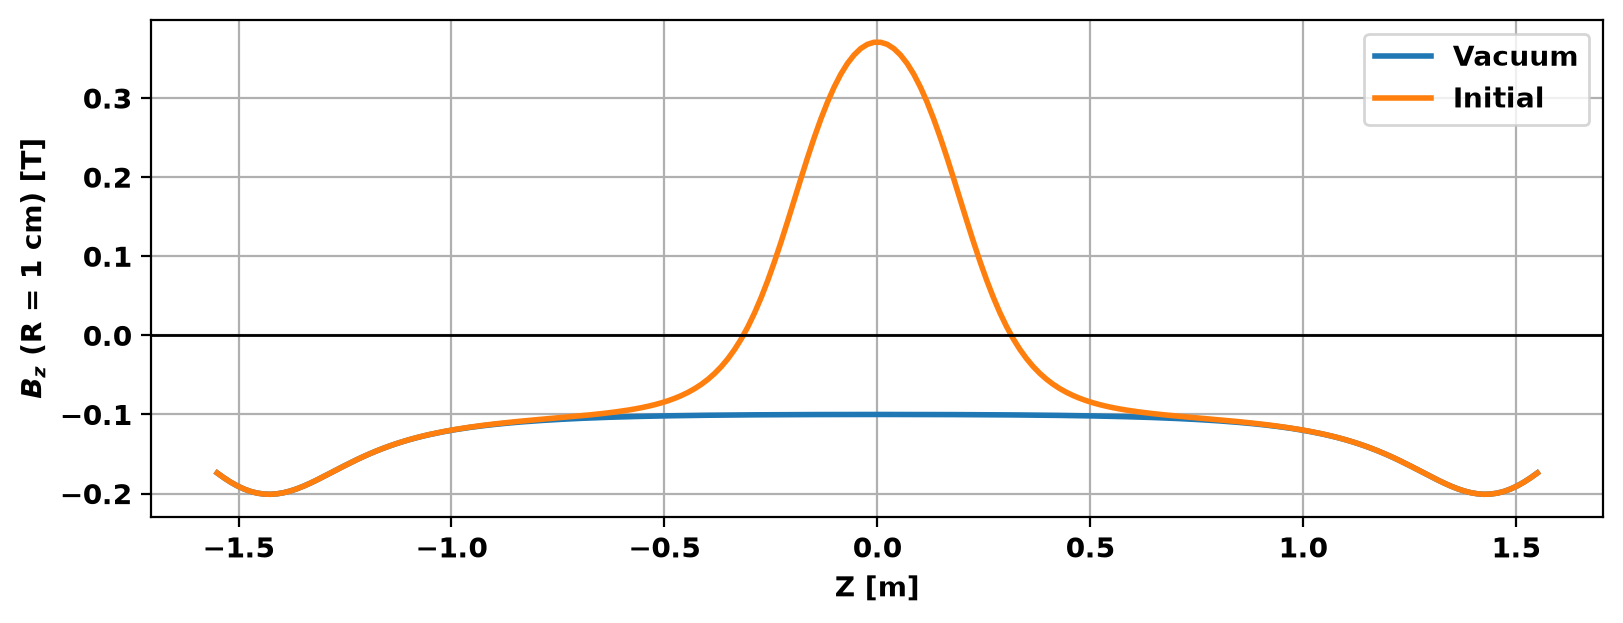

In [13]:
# Plot flux surfaces
fig, ax = plt.subplots(1,1,figsize=(10,3),constrained_layout=True)
mygs.plot_machine(fig,ax)
mygs.plot_psi(fig,ax,xpoint_color=None)
ax.set_xlabel('Z [m]')
ax.set_ylabel('R [m]')

# Plot axial field on axis
mygs.set_psi(psi_init)
field_eval = mygs.get_field_eval('B')
Bz_init = np.zeros(z_axis.shape)
for i, z in enumerate(z_axis):
    Bz_init[i] = field_eval.eval(np.r_[eval_r,z])[2]
fig, ax = plt.subplots(1,1,figsize=(8,3),constrained_layout=True)
ax.plot(z_axis,Bz_vac,label='Vacuum')
ax.plot(z_axis,Bz_init,label='Initial')
ax.axhline(0.0,color='k',lw=1)
ax.grid(True)
ax.legend()
ax.set_xlabel('Z [m]')
_ = ax.set_ylabel(r'$B_z$ (R = 1 cm) [T]')

### Perform equilibrium solve
Now we solve for the equilibrium using the targets set above (`Ip=200 kA` and `Ip_ratio=0`) with \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.solve "solve()". As the solver converges slowly for this case we also increase the maximum number of iterations.

In [14]:
mygs.settings.maxits=200
mygs.settings.nl_tol=1.E-7
mygs.update_settings()

EQ_frc = mygs.solve()

Starting non-linear GS solver
     1  0.0000E+00  6.9144E+00  2.6155E-03  2.2255E-01 -1.3569E-05 -0.0000E+00
     2 -1.3951E-17  6.0900E+00  1.8943E-03  2.2887E-01 -1.1609E-05 -0.0000E+00
     3  0.0000E+00  5.5342E+00  1.3672E-03  2.3133E-01 -3.2766E-05 -0.0000E+00
     4 -3.5360E-18  5.1944E+00  9.0321E-04  2.3159E-01 -2.4274E-05 -0.0000E+00
     5 -3.7480E-18  4.9740E+00  5.6647E-04  2.3141E-01 -2.2836E-05 -0.0000E+00
     6  0.0000E+00  4.8292E+00  3.5620E-04  2.3088E-01 -4.1183E-05 -0.0000E+00
     7 -1.3951E-17  4.7402E+00  2.4864E-04  2.3016E-01 -3.7768E-05 -0.0000E+00


     8 -1.3951E-17  4.6882E+00  2.0763E-04  2.2933E-01 -4.2506E-05 -0.0000E+00
     9 -4.1733E-18  4.6603E+00  1.9404E-04  2.2847E-01 -2.7667E-05 -0.0000E+00
    10  0.0000E+00  4.6476E+00  1.8588E-04  2.2764E-01 -2.5149E-05 -0.0000E+00
    11  0.0000E+00  4.6445E+00  1.7626E-04  2.2686E-01 -3.7188E-05 -0.0000E+00
    12  0.0000E+00  4.6473E+00  1.6411E-04  2.2615E-01 -4.7368E-05 -0.0000E+00
    13 -4.3317E-18  4.6535E+00  1.4995E-04  2.2551E-01 -2.8599E-05 -0.0000E+00
    14  0.0000E+00  4.6614E+00  1.3498E-04  2.2494E-01 -2.4233E-05 -0.0000E+00
    15  1.3951E-17  4.6701E+00  1.1998E-04  2.2445E-01 -1.8371E-05 -0.0000E+00


    16  0.0000E+00  4.6788E+00  1.0569E-04  2.2401E-01 -3.3303E-05 -0.0000E+00
    17 -4.4221E-18  4.6873E+00  9.2450E-05  2.2363E-01 -4.1007E-05 -0.0000E+00
    18  0.0000E+00  4.6953E+00  8.0414E-05  2.2331E-01 -4.7327E-05 -0.0000E+00
    19 -1.3951E-17  4.7025E+00  6.9597E-05  2.2303E-01 -4.4597E-05 -0.0000E+00
    20  1.3951E-17  4.7091E+00  5.9986E-05  2.2280E-01 -4.3983E-05 -0.0000E+00
    21  1.3951E-17  4.7149E+00  5.1530E-05  2.2260E-01 -3.5712E-05 -0.0000E+00
    22  0.0000E+00  4.7201E+00  4.4091E-05  2.2242E-01 -3.3580E-05 -0.0000E+00
    23  1.3951E-17  4.7246E+00  3.7632E-05  2.2228E-01 -2.8193E-05 -0.0000E+00


    24  0.0000E+00  4.7286E+00  3.2022E-05  2.2215E-01 -2.5278E-05 -0.0000E+00
    25  0.0000E+00  4.7320E+00  2.7200E-05  2.2205E-01 -2.2859E-05 -0.0000E+00
    26  0.0000E+00  4.7349E+00  2.3044E-05  2.2196E-01 -2.0804E-05 -0.0000E+00
    27  1.3951E-17  4.7375E+00  1.9452E-05  2.2188E-01 -2.0351E-05 -0.0000E+00
    28  0.0000E+00  4.7396E+00  1.6410E-05  2.2182E-01 -2.0036E-05 -0.0000E+00
    29 -4.4822E-18  4.7415E+00  1.3811E-05  2.2177E-01 -1.9415E-05 -0.0000E+00
    30  0.0000E+00  4.7430E+00  1.1608E-05  2.2173E-01 -2.0576E-05 -0.0000E+00
    31  0.0000E+00  4.7443E+00  9.7476E-06  2.2169E-01 -2.0739E-05 -0.0000E+00


    32  1.3951E-17  4.7454E+00  8.1678E-06  2.2166E-01 -2.0451E-05 -0.0000E+00
    33  0.0000E+00  4.7464E+00  6.8355E-06  2.2163E-01 -1.9206E-05 -0.0000E+00
    34  0.0000E+00  4.7472E+00  5.7147E-06  2.2161E-01 -1.9214E-05 -0.0000E+00
    35  0.0000E+00  4.7478E+00  4.7742E-06  2.2159E-01 -1.8964E-05 -0.0000E+00
    36  1.3951E-17  4.7484E+00  3.9857E-06  2.2158E-01 -1.8947E-05 -0.0000E+00
    37  0.0000E+00  4.7488E+00  3.3261E-06  2.2157E-01 -1.8727E-05 -0.0000E+00
    38 -1.3951E-17  4.7492E+00  2.7745E-06  2.2155E-01 -1.8687E-05 -0.0000E+00
    39  0.0000E+00  4.7496E+00  2.3101E-06  2.2155E-01 -1.8768E-05 -0.0000E+00


    40  0.0000E+00  4.7498E+00  1.9195E-06  2.2154E-01 -1.9055E-05 -0.0000E+00
    41  0.0000E+00  4.7501E+00  1.5933E-06  2.2153E-01 -1.9477E-05 -0.0000E+00
    42  0.0000E+00  4.7503E+00  1.3227E-06  2.2153E-01 -1.9910E-05 -0.0000E+00
    43  0.0000E+00  4.7504E+00  1.0977E-06  2.2152E-01 -2.0258E-05 -0.0000E+00
    44  0.0000E+00  4.7505E+00  9.1046E-07  2.2152E-01 -2.0611E-05 -0.0000E+00
    45  0.0000E+00  4.7506E+00  7.5502E-07  2.2152E-01 -2.0916E-05 -0.0000E+00
    46  1.3951E-17  4.7507E+00  6.2586E-07  2.2152E-01 -2.1171E-05 -0.0000E+00
    47  0.0000E+00  4.7508E+00  5.1859E-07  2.2151E-01 -2.1380E-05 -0.0000E+00


    48  0.0000E+00  4.7509E+00  4.2955E-07  2.2151E-01 -2.1553E-05 -0.0000E+00
    49 -1.3951E-17  4.7509E+00  3.5571E-07  2.2151E-01 -2.1699E-05 -0.0000E+00
    50  0.0000E+00  4.7510E+00  2.9450E-07  2.2151E-01 -2.1819E-05 -0.0000E+00
    51  1.3951E-17  4.7510E+00  2.4377E-07  2.2151E-01 -2.1919E-05 -0.0000E+00
    52  0.0000E+00  4.7510E+00  2.0173E-07  2.2151E-01 -2.2000E-05 -0.0000E+00
    53 -4.4825E-18  4.7511E+00  1.6692E-07  2.2151E-01 -2.2066E-05 -0.0000E+00
    54 -4.4825E-18  4.7511E+00  1.3810E-07  2.2151E-01 -2.2122E-05 -0.0000E+00
    55 -4.4825E-18  4.7511E+00  1.1422E-07  2.2151E-01 -2.2168E-05 -0.0000E+00


    56 -4.4825E-18  4.7511E+00  9.4464E-08  2.2151E-01 -2.2206E-05 -0.0000E+00
 Timing:   1.6006410000845790     
   Source:    0.83217300008982420     
   Solve:     0.49606200028210878     
   Boundary:   1.7453002743422985E-002
   Other:     0.25495299696922302     


### Plot equilibrium
We now plot the converged flux surfaces (black) along with the initial flux surfaces (red) and the current in each coil. We also compare the current in each coil to the vacuum (bias field) currents, which shows how the flux-conserving coils near the FRC carry additional current to compress the external field.

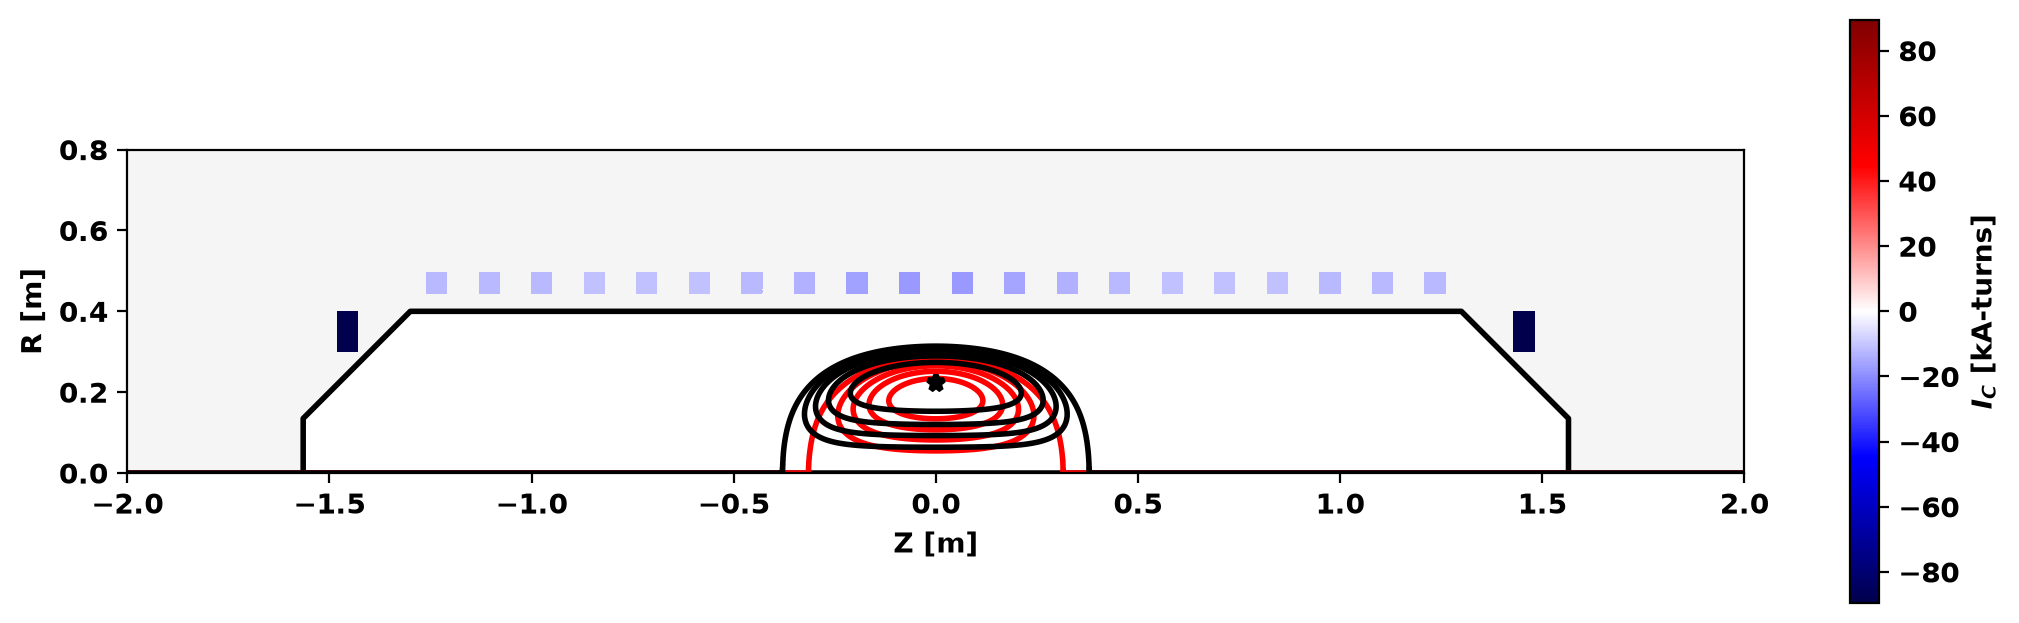

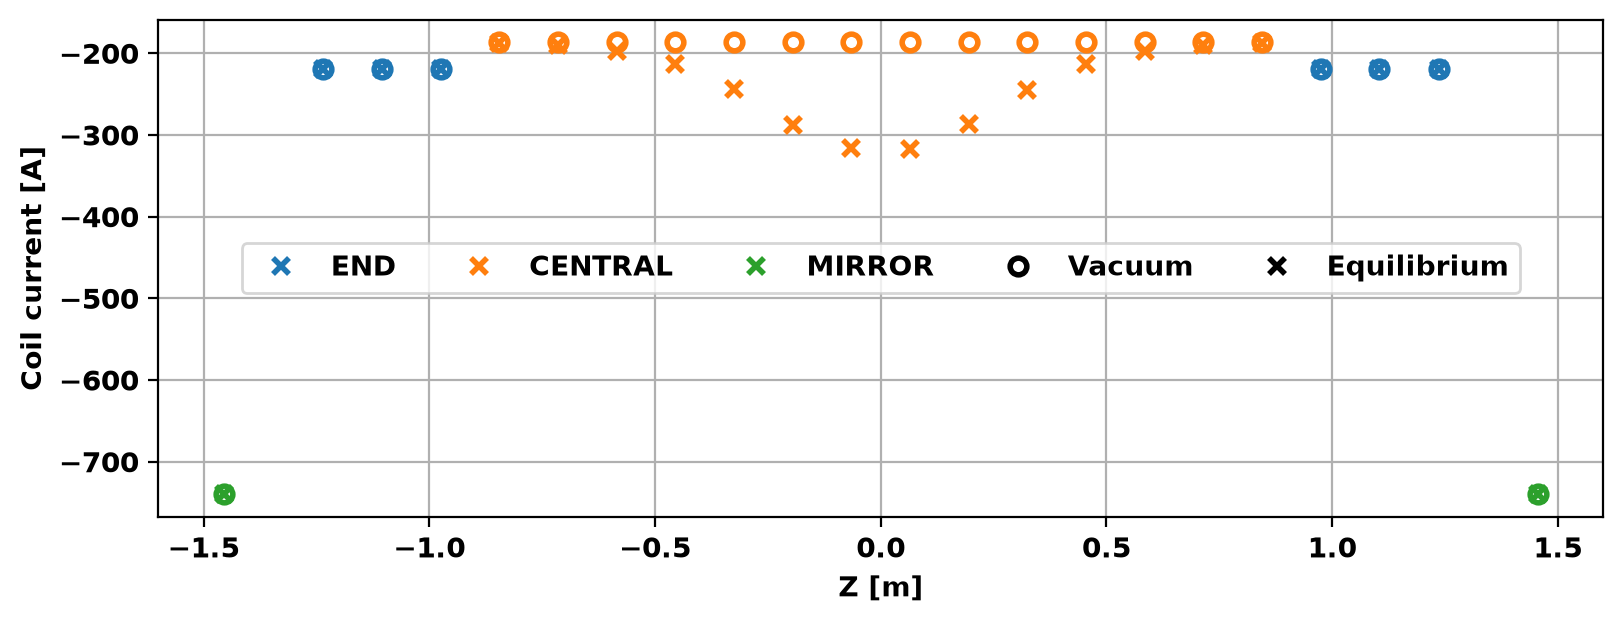

In [15]:
# Plot flux surfaces
fig, ax = plt.subplots(1,1,figsize=(10,3),constrained_layout=True)
mygs.plot_machine(fig,ax,coil_colormap='seismic',coil_symmap=True,coil_scale=1.E-3,coil_clabel=r'$I_C$ [kA-turns]')
mygs.plot_psi(fig,ax,psi=psi_init_norm,plasma_nlevels=6,plasma_color='r',vacuum_nlevels=0,xpoint_color=None,opoint_color=None)
mygs.plot_psi(fig,ax,plasma_nlevels=6,plasma_color='k',vacuum_nlevels=0,xpoint_color=None)
ax.set_xlabel('Z [m]')
ax.set_ylabel('R [m]')

# Compare coil currents to vacuum
eq_currents, _ = EQ_frc.get_coil_currents()
fig, ax = plt.subplots(1,1,figsize=(8,3),constrained_layout=True)
for group_name in coil_groups:
    zc = [coil_pts[coil_names.index(coil_name),1] for coil_name in coil_groups[group_name]]
    I_vac = [coil_currents[coil_name] for coil_name in coil_groups[group_name]]
    I_eq = [eq_currents[coil_name] for coil_name in coil_groups[group_name]]
    lines = ax.plot(zc,I_vac,'o',fillstyle='none')
    ax.plot(zc,I_eq,'x',color=lines[0].get_color(),label=group_name)
ax.plot([],[],'ko',fillstyle='none',label='Vacuum')
ax.plot([],[],'kx',label='Equilibrium')
ax.grid(True)
ax.legend(ncol=5,loc='center')
ax.set_xlabel('Z [m]')
_ = ax.set_ylabel('Coil current [A]')

### FRC parameters
Standard TokaMaker equilibrium statistics (eg. \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.print_info "print_info()") assume a tokamak-like geometry, where the plasma boundary does not include the geometric axis, so instead we compute a few standard FRC parameters directly:
 - $r_s$: The separatrix radius at the midplane, where $\psi = 0$
 - $R$: The radius of the field null (O-point), which for an FRC is expected to be $\approx r_s / \sqrt{2}$
 - $l_s$: The separatrix length, given by the distance between the X-points on the geometric axis (where $B_z = 0$)
 - $x_s = r_s / r_c$: The ratio of the separatrix radius to the flux conserver radius ($r_c \approx 0.47$ m)
 - $B_e$: The external field at the midplane at the plasma tube wall, which is compared to the expected value from flux compression $B_e \approx B_0 / (1 - x_s^2)$ for a long FRC
 - $\phi_p = 2 \pi \psi_{O}$: The poloidal flux trapped inside the separatrix
 - $\langle P \rangle$: The volume-averaged pressure inside the separatrix

In [16]:
psi_eval = EQ_frc.get_field_eval('psi')
B_eval = EQ_frc.get_field_eval('B')
P_eval = EQ_frc.get_field_eval('P')

# Midplane profiles
r_mid = np.linspace(1.E-3,0.399,400)
psi_mid = np.zeros(r_mid.shape)
Bz_mid = np.zeros(r_mid.shape)
P_mid = np.zeros(r_mid.shape)
for i, r in enumerate(r_mid):
    psi_mid[i] = psi_eval.eval(np.r_[r,0.0])[0]
    Bz_mid[i] = B_eval.eval(np.r_[r,0.0])[2]
    P_mid[i] = P_eval.eval(np.r_[r,0.0])[0]

# Axial profile (slightly off axis)
Bz_eq = np.zeros(z_axis.shape)
for i, z in enumerate(z_axis):
    Bz_eq[i] = B_eval.eval(np.r_[eval_r,z])[2]

# Separatrix radius (psi = 0) and length (B_z = 0 on axis)
i = np.where(psi_mid > 0.0)[0].max()
r_s = np.interp(0.0,psi_mid[[i+1,i]],r_mid[[i+1,i]])
z_inner = z_axis[z_axis >= 0.0]
Bz_inner = Bz_eq[z_axis >= 0.0]
i = np.where(Bz_inner > 0.0)[0].max()
l_s = 2.0*np.interp(0.0,Bz_inner[[i+1,i]],z_inner[[i+1,i]])

# Derived quantities
R_null = EQ_frc.o_point[0]
r_c = 0.47
x_s = r_s/r_c
B_0 = abs(Bz_vac[np.abs(z_axis).argmin()])
B_e = abs(Bz_mid[-1])
Ip, _, vol, pvol, _, _, _ = EQ_frc.get_globals()

print('Plasma current        = {0:8.2f} [kA]'.format(Ip/1.E3))
print("F*F' scale factor     = {0:8.1E}".format(EQ_frc.alam))
print('Separatrix radius     = {0:8.3f} [m]'.format(r_s))
print('Field null radius     = {0:8.3f} [m] (r_s/sqrt(2) = {1:5.3f})'.format(R_null,r_s/np.sqrt(2.0)))
print('Separatrix length     = {0:8.3f} [m] (elongation = {1:4.2f})'.format(l_s,l_s/(2.0*r_s)))
print('x_s                   = {0:8.3f}'.format(x_s))
print('External field        = {0:8.3f} [T] (B_0/(1-x_s^2) = {1:5.3f})'.format(B_e,B_0/(1.0-x_s**2)))
print('Poloidal flux         = {0:8.2f} [mWb]'.format(2.0*np.pi*EQ_frc.psi_bounds[1]*1.E3))
print('Peak pressure         = {0:8.2f} [kPa]'.format(P_mid.max()/1.E3))
print('Avg. pressure         = {0:8.2f} [kPa]'.format(pvol/vol/1.E3))

Plasma current        =   200.00 [kA]
F*F' scale factor     = -4.5E-18
Separatrix radius     =    0.314 [m]
Field null radius     =    0.222 [m] (r_s/sqrt(2) = 0.222)
Separatrix length     =    0.758 [m] (elongation = 1.21)
x_s                   =    0.668
External field        =    0.170 [T] (B_0/(1-x_s^2) = 0.181)
Poloidal flux         =    12.23 [mWb]
Peak pressure         =    15.18 [kPa]
Avg. pressure         =     8.77 [kPa]


For comparison, the translated FRC in TCS formed with an 8 mTorr fill pressure (Table I of [Hoffman et al. (2002)](https://doi.org/10.13182/FST02-A205)) had $r_s = 25$ cm, $B_e = 0.14$ T, and $\langle n_e \rangle T_t \approx 6.7$ kPa ($\langle n_e \rangle = 2.1 \times 10^{20}$ m$^{-3}$, $T_t = 200$ eV), which are comparable to the values found here.

**Note:** The FRCs observed in TCS are more elongated than the equilibrium found here (eg. the ~2-m-long RMF-formed FRCs in Sec. V of [Hoffman et al. (2002)](https://doi.org/10.13182/FST02-A205)). As discussed above, the elongation can be increased by moving the maximum in $P'$ closer to the separatrix.

Finally, we plot the axial field along the geometric axis for the vacuum and FRC equilibrium, along with the radial profiles of $B_z$ and pressure at the midplane.

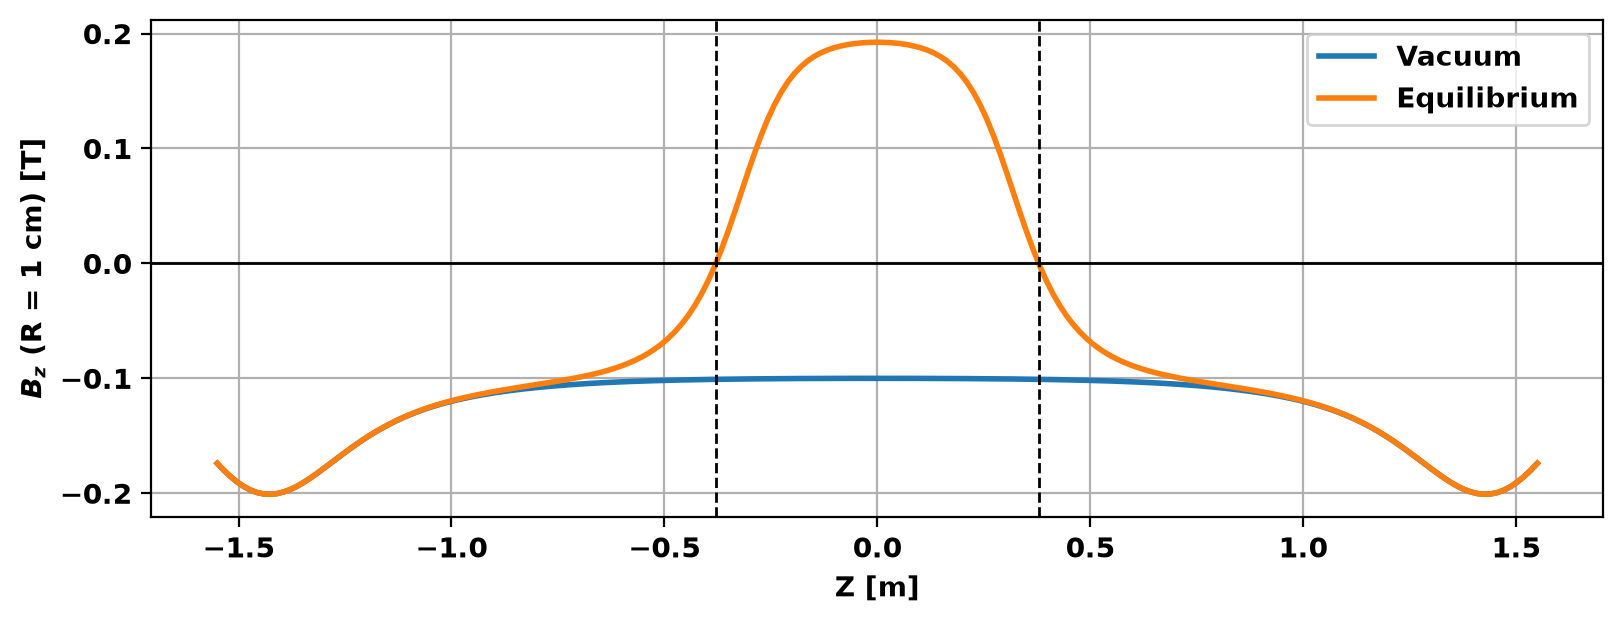

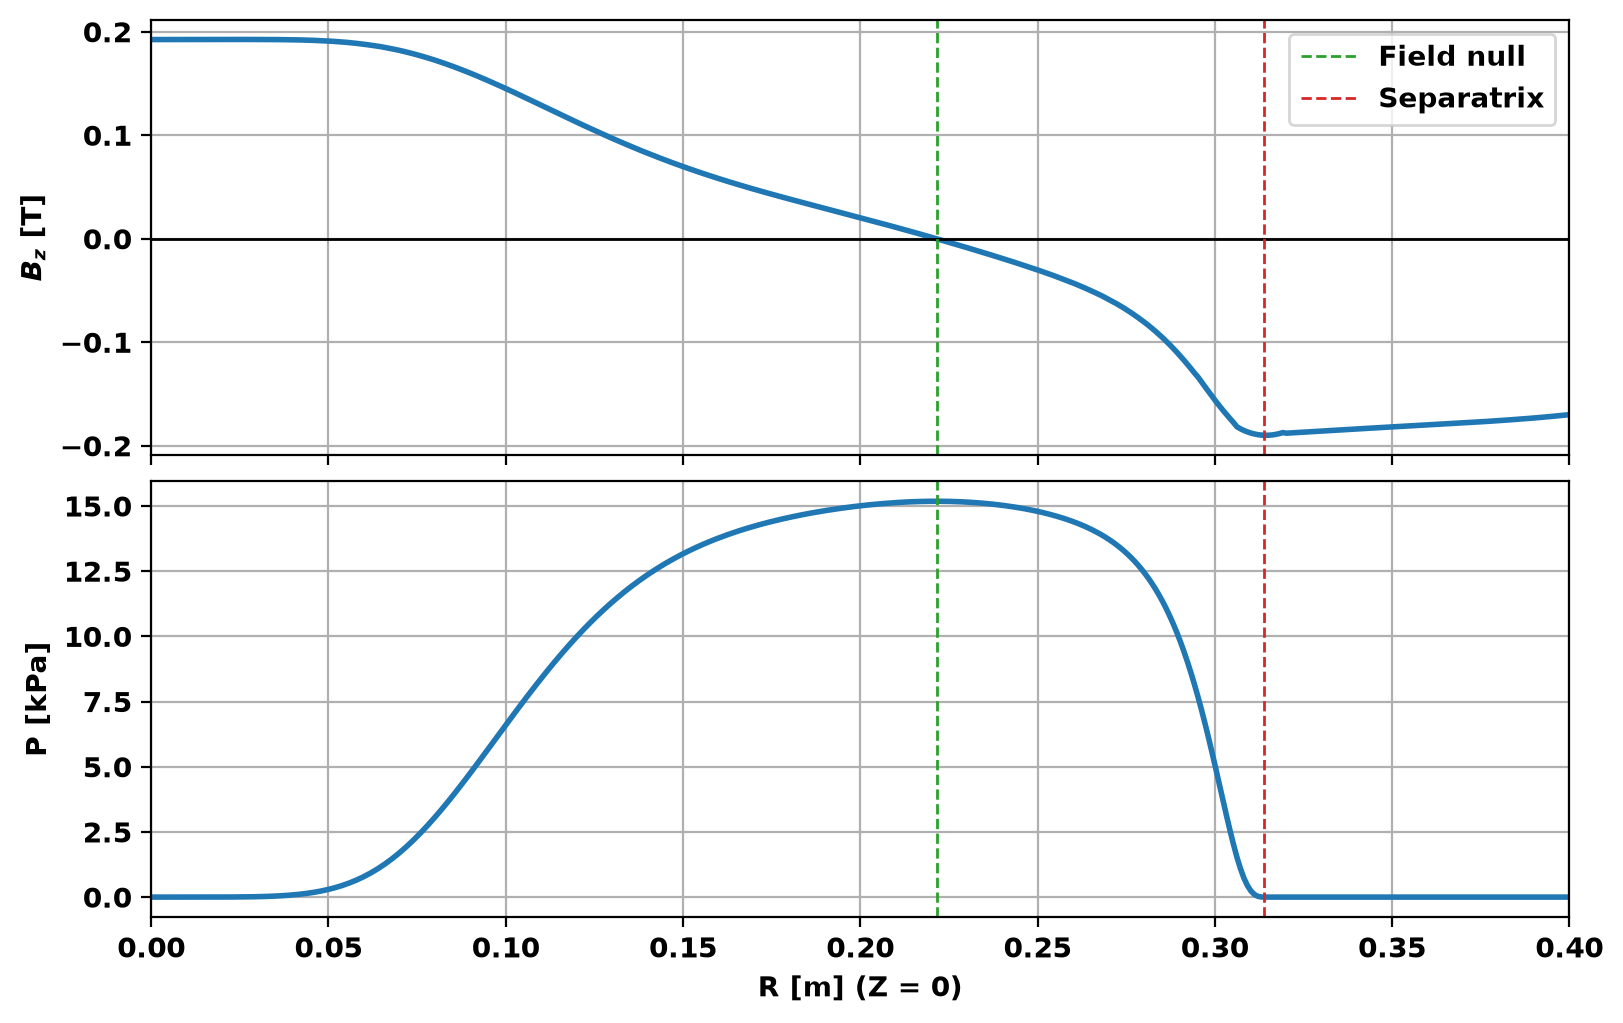

In [17]:
# Plot axial field on axis
fig, ax = plt.subplots(1,1,figsize=(8,3),constrained_layout=True)
ax.plot(z_axis,Bz_vac,label='Vacuum')
ax.plot(z_axis,Bz_eq,label='Equilibrium')
ax.axhline(0.0,color='k',lw=1)
for z in (-l_s/2.0,l_s/2.0):
    ax.axvline(z,color='k',ls='--',lw=1)
ax.grid(True)
ax.legend()
ax.set_xlabel('Z [m]')
_ = ax.set_ylabel(r'$B_z$ (R = 1 cm) [T]')

# Plot midplane profiles
fig, ax = plt.subplots(2,1,sharex=True,figsize=(8,5),constrained_layout=True)
ax[0].plot(r_mid,Bz_mid)
ax[0].axhline(0.0,color='k',lw=1)
ax[0].set_ylabel(r'$B_z$ [T]')
ax[1].plot(r_mid,P_mid/1.E3)
ax[1].set_ylabel('P [kPa]')
for ax_tmp in ax:
    ax_tmp.axvline(R_null,color='tab:green',ls='--',lw=1,label='Field null')
    ax_tmp.axvline(r_s,color='tab:red',ls='--',lw=1,label='Separatrix')
    ax_tmp.grid(True)
ax[0].legend()
ax[-1].set_xlim(0.0,0.4)
_ = ax[-1].set_xlabel('R [m] (Z = 0)')